# 22 · Autoencoder: 작은 좌표로 접고 다시 펼치기

**이번 질문:** 784개 화소를 16개 숫자로 줄였다가 다시 펼칠 때, 무엇을 남기고 무엇을 잃을까요? 그 압축 규칙을 데이터에서 배울 수 있을까요?

11번 PCA는 분산이 큰 직선 방향들을 골랐습니다. 이번에는 **작은 잠재 좌표를 사이에 둔 신경망 두 개**를 만들고, 원래 입력을 잘 복원하도록 두 신경망을 함께 학습합니다. 선형일 때 PCA와 만나는 지점, 비선형으로 바뀌는 지점, 잡음 제거 목적을 구분합니다.

- 준비물: [00](../00_기초/00_math_to_numpy.ipynb)의 행렬·축, [01](../00_기초/01_gradients_and_learning.ipynb)의 역전파·중심차분, [03](../00_기초/03_perceptron_to_mlp.ipynb)의 MLP, [04](../00_기초/04_optimizers.ipynb)의 Adam, [11](../02_연결/11_linear_algebra.ipynb)의 중심화·PCA 투영입니다.
- 도착점: 손계산 → 선형 AE와 PCA → 비선형 AE 전체 미분 → MNIST 복원 비교 → denoising AE를 NumPy로 잇습니다.
- 다음 연결: [27](27_monte_carlo_gradients.ipynb)에서 잡음에 대한 기대값과 샘플 기울기를 공부하고, [25](25_vae.ipynb)에서 잠재 사전분포와 ELBO가 추가된 VAE로 넘어갑니다. VAE의 사전 준비는 [학습 경로](../../docs/CURRICULUM.md)를 따릅니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 설명·수식·구현 | 코드를 가리고 다시 구성합니다 |
| 🔍 확인 | 그림 해석·검산 결과 | 주장과 실제 숫자를 맞춰 봅니다 |
| 📎 참고 | 환경·보충 설명 | 필요할 때 돌아옵니다 |
| ✏️ 연습 | 핵심 한두 줄을 바꾸기 | 손으로 예상한 뒤 독립 검사 셀을 실행합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 구조는 $x\rightarrow z\rightarrow r$이고, 목적은 $r$이 입력과 같아지도록 만드는 것입니다. 병목의 크기와 손실의 정의는 서로 다른 선택입니다.
2. 중심화한 선형 AE의 **최소 제곱오차 복원 부분공간**은 PCA와 연결됩니다. 잠재 좌표의 축이나 크기까지 PCA와 같아지는 것은 아닙니다.
3. 잡음 제거에서는 입력은 손상시키되 타깃은 깨끗하게 유지합니다. 보통 AE에는 잠재 사전분포가 없으므로 임의의 정규분포 샘플을 decoder에 넣는 생성 규칙이 자동으로 생기지 않습니다.

| 기호 | shape | 뜻 |
|---|---|---|
| $X,T,R$ | $(N,D)$ | 입력·복원 타깃·모델 출력. 첫 축은 표본, 둘째 축은 화소 |
| $A,B$ | $(N,H)$ | encoder·decoder의 은닉 출력 |
| $Z$ | $(N,L)$ | 잠재 좌표. 이 실험은 $L=16<D=784$ |
| $W_1,W_z,W_2,W_o$ | $(D,H),(H,L),(L,H),(H,D)$ | 네 선형 층의 가중치 |
| $b_1,b_z,b_2,b_o$ | $(H,),(L,),(H,),(D,)$ | 배치 축으로 더하는 편향 |

[글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/autoencoder_plots.py)

In [1]:
# 준비 셀: 프로젝트 경로, 공통 도구와 그림 도구를 불러옵니다.
import sys
from pathlib import Path
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
from time import perf_counter
from src.utils import setup_plots, run_check
from src.data.mnist import load_mnist, load_examples
from src.utils.autoencoder_plots import (
    plot_linear_flow, plot_pca_projection, plot_nonlinear_flow,
    plot_comparison_setup, plot_training_history, plot_reconstruction_rows,
    plot_denoising_flow,
)
setup_plots()
print("NumPy", np.__version__, "· Autoencoder 준비 완료")

NumPy 2.4.6 · Autoencoder 준비 완료


📎 **실행 환경과 수치 규칙**

필요한 라이브러리는 NumPy·Matplotlib이고, 커널 실행에는 Jupyter가 필요합니다. MNIST 파일은 프로젝트의 데이터 로더로 내려받습니다. CPU에서 작은 배치를 학습하며, 표본 수·잠재 차원·epoch는 평가 결과를 보기 전에 고정합니다. 모든 난수는 용도별 `default_rng(seed)`로 분리합니다. 작은 행렬에서 BLAS 스레드 생성 비용이 크다면 커널을 시작하기 전에 `OPENBLAS_NUM_THREADS=1`, `OMP_NUM_THREADS=1`을 지정할 수 있습니다.

손실은 노트북 전체에서 $J=\frac{1}{2ND}\sum_{n,d}(R_{nd}-T_{nd})^2$입니다. 따라서 $dR=(R-T)/(ND)$입니다. 보고 표의 **MSE는 $2J$**이며 이미지 수와 화소 수를 모두 평균합니다. 출력층은 선형이므로 값이 $[0,1]$ 밖으로 나갈 수 있습니다. 그림은 이 범위로 보이지만 손실·평가에서는 자르지 않습니다.

> **코드** · `@`는 행렬 곱, `*`는 같은 위치끼리의 곱입니다. `axis=0`은 표본 축을 합치고, `keepdims=True`는 길이 1인 축을 남깁니다. `array[:, :L]`은 모든 행에서 앞 $L$개 열을 고릅니다.

> **용어** · **MNIST**는 0–9의 손글씨 숫자를 담은 자료입니다. 각 그림은 28×28개의 **화소(pixel)**로 이루어지며, 이 노트북에서는 잉크 양을 0–1로 나타내고 784개의 벡터로 펼칩니다. **MSE(mean squared error)**는 잔차의 제곱을 표본과 화소에 걸쳐 평균한 값입니다.

## 🔑 1. 작은 좌표로 접고 다시 펼치기

**이 절에서 가져갈 것:** encoder·decoder·병목과 재구성 손실을 두 표본의 숫자로 설명합니다.

두 화소짜리 그림이 $(1,3)$과 $(3,1)$이라고 합시다. 두 값을 평균 하나로 저장하면 둘 다 $2$가 됩니다. 그 하나로 원래 두 값을 되살리는 것은 불가능합니다. 그래도 복원 결과와 원래 입력의 차이를 재면, 어떤 압축 규칙이 더 나은지 비교할 수 있습니다.

> **용어** · **encoder(부호화기)**는 입력을 작은 좌표 $z=f_\theta(x)$로 바꾸는 함수입니다. **decoder(복호화기)**는 그 좌표를 입력 크기로 펼치는 함수 $r=g_\phi(z)$입니다. 두 함수를 함께 **autoencoder(AE, 자동부호화기)**라고 합니다.
>
> **용어** · **병목(bottleneck)**은 중간 표현의 차원 $L$을 작게 제한하는 자리입니다. **재구성(reconstruction)**은 원래 입력을 타깃으로 삼아 복원하는 작업입니다. 이름에 encoder가 들어가도 파일 용량을 줄이는 부호화 형식까지 정한 것은 아닙니다.

행마다 표본 하나를 두면 선형 AE는

$$X\in\mathbb R^{N\times D},\quad W_e\in\mathbb R^{D\times L},\quad W_d\in\mathbb R^{L\times D},\qquad Z=XW_e,\quad R=ZW_d.$$

손으로 $W_e=(1/2,1/2)^T$, $W_d=(1,1)$을 넣으면

$$X=\begin{bmatrix}1&3\\3&1\end{bmatrix},\quad Z=\begin{bmatrix}2\\2\end{bmatrix},\quad R=\begin{bmatrix}2&2\\2&2\end{bmatrix},\qquad J=\frac{1+1+1+1}{2\cdot2\cdot2}=\frac12.$$

두 입력이 같은 좌표로 접히면 decoder는 둘을 구별하지 못합니다. 다음 그림은 이 계산을 그대로 나란히 놓은 것입니다.

In [2]:
# 개념 그림용 계산: 행마다 표본 하나, 열마다 화소 하나입니다.
hand_x = np.array([[1., 3.], [3., 1.]])
hand_we = np.array([[0.5], [0.5]])
hand_wd = np.array([[1., 1.]])
hand_z = hand_x @ hand_we
hand_r = hand_z @ hand_wd
hand_residual = hand_r - hand_x
hand_loss = 0.5 * np.mean(hand_residual ** 2)

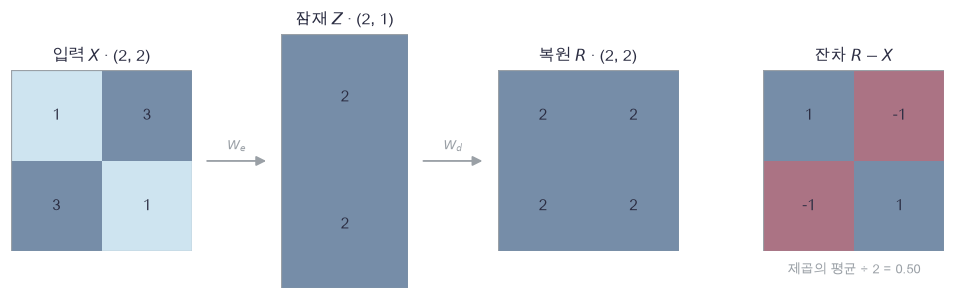

In [3]:
plot_linear_flow(hand_x, hand_z, hand_r, hand_residual, hand_loss)

🔍 **그림 확인**

가운데 좌표는 두 행 모두 $2$입니다. 잔차의 부호는 반대여도 제곱오차는 같습니다. 차원을 줄이는 것만으로 좋은 표현을 얻는 것은 아닙니다. **어떤 방향을 남길지를 데이터의 재구성 손실로 학습**해야 합니다.

먼저 합의 축을 반복문으로 펼칩니다. encoder의 $Z_{nk}=\sum_dX_{nd}(W_e)_{dk}$에서 $d$가 사라지고, decoder의 $R_{nd}=\sum_kZ_{nk}(W_d)_{kd}$에서는 $k$가 사라집니다. 이어서 같은 합을 `@` 한 번씩으로 적습니다.

In [4]:
def linear_ae_loops(x, encoder, decoder):
    """표본·화소·잠재 축을 반복문으로 합해 선형 AE를 계산합니다."""
    n_samples, n_features = x.shape
    latent_dim = encoder.shape[1]
    z = np.zeros((n_samples, latent_dim))
    restored = np.zeros_like(x)
    for n in range(n_samples):
        for k in range(latent_dim):
            for d in range(n_features):
                z[n, k] += x[n, d] * encoder[d, k]
    for n in range(n_samples):
        for d in range(n_features):
            for k in range(latent_dim):
                restored[n, d] += z[n, k] * decoder[k, d]
    return z, restored

In [5]:
def linear_ae(x, encoder, decoder):
    """두 행렬 곱으로 잠재 좌표 (N,L)와 복원 (N,D)을 반환합니다."""
    z = x @ encoder
    restored = z @ decoder
    return z, restored

In [6]:
def reconstruction_loss(restored, target):
    """표본·화소 평균 제곱오차의 절반과 출력에 대한 기울기를 반환합니다."""
    assert restored.shape == target.shape, "출력과 타깃의 shape가 같아야 합니다"
    residual = restored - target
    loss = 0.5 * np.mean(residual ** 2)
    drestored = residual / target.size
    return float(loss), drestored

In [7]:
# 쓰는 것: hand_x, hand_we, hand_wd, hand_z, hand_r, hand_loss (1절 손계산)
loop_z, loop_r = linear_ae_loops(hand_x, hand_we, hand_wd)
vector_z, vector_r = linear_ae(hand_x, hand_we, hand_wd)
np.testing.assert_allclose(loop_z, hand_z)  # 검산: 반복문 잠재 좌표는 두 행 모두 2입니다.
np.testing.assert_allclose(loop_r, vector_r)  # 검산: 반복문과 행렬 곱의 복원이 같습니다.
loss_hand, gradient_hand = reconstruction_loss(vector_r, hand_x)
np.testing.assert_allclose(loss_hand, 0.5)  # 검산: 손계산의 제곱오차 절반은 0.5입니다.
np.testing.assert_allclose(gradient_hand, [[0.25, -0.25], [-0.25, 0.25]])  # 검산: 기울기는 잔차를 네 화소로 나눈 값입니다.
print("손계산 = 반복문 = 벡터화 · J =", loss_hand)

손계산 = 반복문 = 벡터화 · J = 0.5


### ✏️ 연습 1 · 평균 좌표 하나로 복원하기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

encoder는 두 화소의 평균을 좌표 하나에 저장합니다. `z`, `restored`를 각각 한 줄로 채우세요. 입력 `x`의 shape는 `(N,2)`입니다.

In [8]:
def exercise_average_code(x):
    """두 화소의 평균 하나로 같은 값 두 개를 복원합니다."""
    raise NotImplementedError
    return z, restored

In [9]:
def check_average_code(candidate):
    """평균이 3인 손계산 한 표본으로 압축·복원 shape를 검사합니다."""
    z, restored = candidate(np.array([[2., 4.]]))
    assert z.shape == (1, 1), "잠재 축을 길이 1로 남겨야 합니다"
    np.testing.assert_allclose(z, [[3.]])  # 검산: 2와 4의 평균은 3입니다.
    np.testing.assert_allclose(restored, [[3., 3.]])  # 검산: 하나의 좌표를 두 화소에 반복합니다.
run_check(check_average_code, exercise_average_code)

☐ exercise_average_code: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
z = np.mean(x, axis=1, keepdims=True)
restored = z @ np.ones((1, 2))
```

</details>

## 🔑 2. 선형 병목의 최적 복원은 PCA 투영

**이 절에서 가져갈 것:** 학습 자료의 평균을 뺀 선형 AE가 최소화하는 복원과 PCA의 관계를 쓰고, 잠재 기저의 비유일성을 설명합니다.

가로로 크게 퍼지고 세로로 조금 퍼진 점 네 개를 좌표 하나에 담는다고 합시다. 가로 좌표를 남기면 큰 변동은 보존하고 작은 세로 변동을 잃습니다. 이것이 11번 PCA에서 본 투영입니다.

> **용어** · **중심화**는 학습 표본의 평균 $m$을 빼는 것입니다. **투영**은 선택한 부분공간 위의 가장 가까운 점으로 옮기는 연산입니다. **기저**는 같은 부분공간의 좌표를 적는 데 쓰는 독립적인 방향들입니다.

$$m=\frac1N\sum_nX_n\in\mathbb R^{1\times D},\quad X_c=X-m=U\Sigma V^T,\quad V_L=V[:, :L].$$

중심화된 선형 AE에 편향이 없고 $L<D$이면, 복원 $X_cW_eW_d$의 rank는 $L$ 이하입니다. 제곱오차를 최소로 만드는 복원 하나는

$$W_e=V_L,\quad W_d=V_L^T,\quad R_c=X_cV_LV_L^T,\quad R=R_c+m.$$

$V_L^TV_L=I$라서 잔차는 남긴 방향에 직교합니다. SVD의 뒤쪽 성분만 사라지므로 최소 손실은

$$J_* = \frac{1}{2ND}\sum_{k>L}\sigma_k^2.$$

경계의 특잇값이 같은 경우에는 최적인 부분공간도 여러 개일 수 있습니다. 고유한 부분공간이 정해져도 잠재 좌표는 유일하지 않습니다. 임의의 가역 행렬 $Q\in\mathbb R^{L\times L}$에 대해

$$W'_e=V_LQ,\quad W'_d=Q^{-1}V_L^T,\quad Z'=X_cV_LQ,\qquad W'_eW'_d=V_LV_L^T.$$

즉 **복원은 같고 잠재 좌표의 크기·방향은 다를 수 있습니다.** AE를 학습한다고 PCA 축의 순서·부호·단위가 자동으로 정해지는 것은 아닙니다. 다음은 가로축만 남기는 경우입니다.

In [10]:
# 그림용 손계산: 평균은 이미 0이고 가로축의 제곱합이 더 큽니다.
projection_x = np.array([[2., 0.], [-2., 0.], [0., 1.], [0., -1.]])
projection_basis = np.array([[1.], [0.]])
projection_z = projection_x @ projection_basis
projection_r = projection_z @ projection_basis.T
projection_residual = projection_x - projection_r

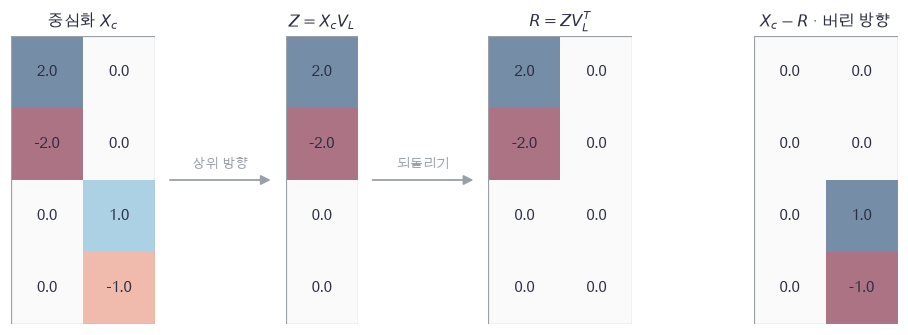

In [11]:
plot_pca_projection(projection_x, projection_z, projection_r, projection_residual)

🔍 **그림 확인**

가로로 놓인 두 점은 정확히 복원되지만 세로의 두 점은 원점으로 갑니다. 버린 성분의 제곱합은 $1+1=2$이므로 $J_*=2/(2\cdot4\cdot2)=0.125$입니다.

아래 `fit_pca`는 SVD로 **닫힌식 최적 복원**을 구합니다. 학습 평균과 기저를 반환하고, 나중에 들어온 validation/test 자료에도 그대로 재사용합니다. test 자료의 평균을 새로 맞추면 다른 변환을 평가하게 됩니다.

In [12]:
def fit_pca(x, latent_dim):
    """학습 행렬에서만 평균과 상위 오른쪽 특이벡터를 맞춥니다."""
    mean = np.mean(x, axis=0, keepdims=True)
    centered = x - mean
    _, singular_values, vt = np.linalg.svd(centered, full_matrices=False)
    basis = vt[:latent_dim].T
    return mean, basis, singular_values

In [13]:
def reconstruct_pca(x, mean, basis):
    """학습 때 저장한 평균·기저로 새 입력을 투영하고 평균을 돌려줍니다."""
    centered = x - mean
    latent = centered @ basis
    restored = latent @ basis.T + mean
    return latent, restored

In [14]:
# 쓰는 것: projection_x (2절 손계산), reconstruction_loss (1절)
toy_mean, toy_basis, toy_singular = fit_pca(projection_x, latent_dim=1)
toy_z, toy_restored = reconstruct_pca(projection_x, toy_mean, toy_basis)
toy_best_loss, _ = reconstruction_loss(toy_restored, projection_x)
toy_tail_loss = np.sum(toy_singular[1:] ** 2) / (2 * projection_x.size)
np.testing.assert_allclose(toy_best_loss, 0.125)  # 검산: 잃은 세로 성분의 제곱합은 2입니다.
np.testing.assert_allclose(toy_best_loss, toy_tail_loss)  # 검산: 복원 오차와 버린 특잇값의 제곱합이 같습니다.
np.testing.assert_allclose((projection_x - toy_restored) @ toy_basis, 0, atol=1e-12)  # 검산: 잔차는 남긴 방향에 직교합니다.
print("PCA 닫힌식 J* =", toy_best_loss)

PCA 닫힌식 J* = 0.125


In [15]:
# 쓰는 것: projection_x, toy_mean, toy_basis (2절 PCA), linear_ae (1절)
scaled_encoder = toy_basis * 3.0
scaled_decoder = toy_basis.T / 3.0
scaled_z, scaled_restored = linear_ae(projection_x - toy_mean, scaled_encoder, scaled_decoder)
np.testing.assert_allclose(scaled_z, toy_z * 3)  # 검산: 잠재 좌표는 세 배가 됩니다.
np.testing.assert_allclose(scaled_restored + toy_mean, toy_restored)  # 검산: decoder가 나누므로 복원은 같습니다.
print("잠재 좌표의 단위는 달라도 복원은 같습니다.")

잠재 좌표의 단위는 달라도 복원은 같습니다.


📎 **닫힌식과 유한 번 학습은 다릅니다**

PCA가 주는 $J_*$는 비교 기준입니다. 무작위 $W_e,W_d$에서 경사하강을 몇 번 했다는 사실만으로 최적점에 도달했다고 말할 수는 없습니다. 다음 작은 학습은 그 차이를 직접 출력합니다. $G=(R-X_c)/(ND)$라 두면

$$dW_d=Z^TG,\qquad dW_e=X_c^T(GW_d^T).$$

두 기울기는 같은 갱신 전 가중치에서 계산한 뒤 함께 갱신합니다. 이 예제는 수렴을 관찰하는 실험이며, 임의 초기화·학습률·epoch에 대한 수렴 보증이 아닙니다.

In [16]:
# 쓰는 것: linear_ae, reconstruction_loss (1절)
def train_tiny_linear(x_centered, latent_dim, steps=400, learning_rate=0.2):
    """작은 중심화 자료에서 선형 encoder·decoder를 함께 경사하강합니다."""
    rng = np.random.default_rng(22)
    encoder = rng.normal(0, 0.2, (x_centered.shape[1], latent_dim))
    decoder = rng.normal(0, 0.2, (latent_dim, x_centered.shape[1]))
    for _ in range(steps):
        z, restored = linear_ae(x_centered, encoder, decoder)
        _, gradient = reconstruction_loss(restored, x_centered)
        ddecoder = z.T @ gradient
        dencoder = x_centered.T @ (gradient @ decoder.T)
        encoder -= learning_rate * dencoder
        decoder -= learning_rate * ddecoder
    return encoder, decoder

In [17]:
# 쓰는 것: projection_x, toy_mean, toy_best_loss (2절), linear_ae, reconstruction_loss (1절)
learned_we, learned_wd = train_tiny_linear(projection_x - toy_mean, 1)
_, learned_toy_r = linear_ae(projection_x - toy_mean, learned_we, learned_wd)
learned_toy_loss, _ = reconstruction_loss(learned_toy_r, projection_x - toy_mean)
assert learned_toy_loss >= toy_best_loss - 1e-12, "선형 rank-1 복원이 PCA 최적값보다 낮을 수 없습니다"
print(f"PCA J*={toy_best_loss:.8f}, 경사하강 J={learned_toy_loss:.8f}, 차이={learned_toy_loss-toy_best_loss:.2e}")

PCA J*=0.12500000, 경사하강 J=0.12500000, 차이=1.38e-14


### ✏️ 연습 2 · 학습 평균으로 새 표본 투영하기

`x_new`는 `(N,D)`, 저장한 `mean`은 `(1,D)`, `basis`는 `(D,L)`입니다. 좌표 `z`와 평균을 되돌린 `restored`를 채우세요.

In [18]:
def exercise_saved_pca(x_new, mean, basis):
    """새 자료에서도 학습 평균과 기저를 그대로 사용합니다."""
    raise NotImplementedError
    return restored

In [19]:
def check_saved_pca(candidate):
    """가로축을 남길 때 세로 값이 학습 평균으로 돌아가는지 검사합니다."""
    actual = candidate(np.array([[5., 9.]]), np.array([[1., 2.]]), np.array([[1.], [0.]]))
    np.testing.assert_allclose(actual, [[5., 2.]])  # 검산: 새 표본의 세로 9가 아니라 학습 평균 2를 씁니다.
run_check(check_saved_pca, exercise_saved_pca)

☐ exercise_saved_pca: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
z = (x_new - mean) @ basis
restored = z @ basis.T + mean
```

</details>

## 🔑 3. 비선형 Autoencoder를 끝까지 미분하기

**이 절에서 가져갈 것:** 네 선형 층과 두 tanh의 forward·backward를 쓰고, 모든 파라미터와 입력 원소를 중심차분으로 확인합니다.

숫자 7의 획이 조금 기울면 화소 변화는 한 직선 방향에만 놓이지 않습니다. encoder와 decoder에 비선형 함수를 넣으면 이런 변화를 더 유연하게 표현할 수 있습니다. 유연성은 좋은 복원을 보장하는 말이 아니므로, 다음 절에서 같은 잠재 차원의 PCA와 실제로 비교합니다.

> **용어** · **잠재 표현(latent representation)**은 입력으로부터 계산한 중간 좌표 $z$입니다. 여기서는 좌표를 결정적으로 계산합니다. **tanh**는 실수를 $(-1,1)$로 눌러 주는 함수이며 도함수는 $1-\tanh^2(u)$입니다.

이번 모델의 구조는 $D\rightarrow H\rightarrow L\rightarrow H\rightarrow D$입니다. 병목 자체와 출력층에는 활성화 함수를 넣지 않습니다.

$$A=\tanh(XW_1+b_1),\quad Z=AW_z+b_z,\quad B=\tanh(ZW_2+b_2),\quad R=BW_o+b_o.$$

$A,B$는 $(N,H)$, $Z$는 $(N,L)$, $R$은 $(N,D)$입니다. 선형 층을 여러 개 쌓아도 비선형 함수가 없으면 행렬 곱 하나로 합쳐집니다. tanh가 들어가야 전체가 선형 투영을 넘어섭니다. 다음 그림은 학습 전의 고정 숫자 7 한 장입니다. 그림에 쓰인 모든 중간 배열을 바로 아래에서 계산합니다.

In [20]:
# 고정 예시: load_examples는 프로젝트 전체에서 같은 MNIST 숫자 0~9를 고릅니다.
example_images, example_labels = load_examples(download=True)
flow_rng = np.random.default_rng(220)
flow_x = example_images[7].reshape(1, 784)
flow_w1 = flow_rng.normal(0, 1 / np.sqrt(784), (784, 64))
flow_wz = flow_rng.normal(0, 1 / np.sqrt(64), (64, 16))
flow_w2 = flow_rng.normal(0, 1 / np.sqrt(16), (16, 64))
flow_wo = flow_rng.normal(0, 1 / np.sqrt(64), (64, 784))
flow_a = np.tanh(flow_x @ flow_w1)
flow_z = flow_a @ flow_wz
flow_b = np.tanh(flow_z @ flow_w2)
flow_r = flow_b @ flow_wo

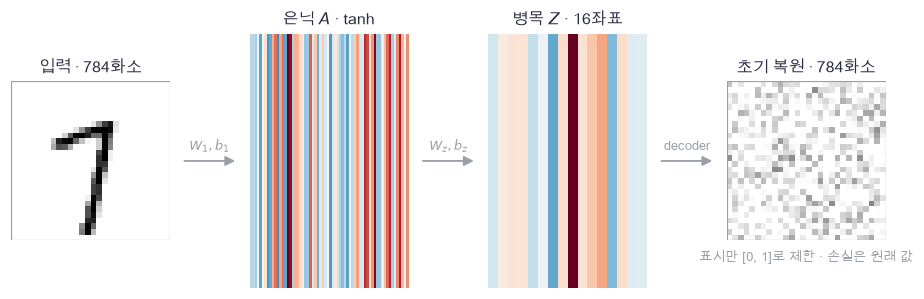

In [21]:
plot_nonlinear_flow(example_images[7], flow_a[0], flow_z[0], flow_r[0].reshape(28, 28))

🔍 **그림 확인**

decoder가 만든 784개 값은 아직 숫자 7과 닮지 않았습니다. 입력 모양을 그대로 되돌리는 규칙은 초기화에 들어 있지 않고 재구성 손실로 배웁니다. 이 개념 그림은 원래 화소를 입력했고, 4절의 학습은 train 평균을 뺀 화소를 입력합니다.

역전파는 오른쪽에서 시작합니다. $T$를 타깃, $G=dR=(R-T)/(ND)$라 두면

$$dW_o=B^TG,\quad db_o=\sum_nG_n,\quad dB=GW_o^T,$$
$$dU_2=dB\odot(1-B^2),\quad dW_2=Z^TdU_2,\quad db_2=\sum_ndU_{2,n},\quad dZ=dU_2W_2^T,$$
$$dW_z=A^TdZ,\quad db_z=\sum_ndZ_n,\quad dA=dZW_z^T,$$
$$dU_1=dA\odot(1-A^2),\quad dW_1=X^TdU_1,\quad db_1=\sum_ndU_{1,n},\quad dX=dU_1W_1^T.$$

$U_1,U_2$는 tanh에 넣기 전의 값입니다. 편향은 모든 표본에 더했으므로 `axis=0`으로 합합니다. 예를 들어 $dW_1$은 $(D,N)@(N,H)=(D,H)$로 원래 $W_1$과 같은 shape입니다.

In [22]:
def init_ae(input_dim, hidden_dim, latent_dim, seed):
    """입력 축 크기로 초기 분산을 조절한 네 가중치와 영 편향을 만듭니다."""
    rng = np.random.default_rng(seed)
    params = {}
    for name, fan_in, fan_out in [
        ("1", input_dim, hidden_dim), ("z", hidden_dim, latent_dim),
        ("2", latent_dim, hidden_dim), ("o", hidden_dim, input_dim),
    ]:
        params["W" + name] = rng.normal(0, 1 / np.sqrt(fan_in), (fan_in, fan_out))
        params["b" + name] = np.zeros(fan_out)
    return params

In [23]:
def ae_forward(x, params):
    """입력 (N,D)을 병목 (N,L)을 거쳐 복원하고 역전파용 중간값을 저장합니다."""
    a = np.tanh(x @ params["W1"] + params["b1"])
    z = a @ params["Wz"] + params["bz"]
    b = np.tanh(z @ params["W2"] + params["b2"])
    restored = b @ params["Wo"] + params["bo"]
    cache = (x, a, z, b)
    return restored, cache

In [24]:
def ae_backward(drestored, cache, params):
    """출력 기울기에서 모든 가중치·편향 및 입력 기울기를 계산합니다."""
    x, a, z, b = cache
    gradients = {}
    # 1) 마지막 선형 층: 화소 축에서 decoder 은닉 축으로 돌아갑니다.
    gradients["Wo"] = b.T @ drestored
    gradients["bo"] = np.sum(drestored, axis=0)
    db = drestored @ params["Wo"].T
    # 2) decoder의 tanh와 선형 층을 지나 잠재 좌표로 갑니다.
    du2 = db * (1 - b ** 2)
    gradients["W2"] = z.T @ du2
    gradients["b2"] = np.sum(du2, axis=0)
    dz = du2 @ params["W2"].T
    # 3) encoder의 선형 병목에서 은닉층으로 갑니다.
    gradients["Wz"] = a.T @ dz
    gradients["bz"] = np.sum(dz, axis=0)
    da = dz @ params["Wz"].T
    # 4) 첫 tanh와 선형 층을 지나 입력으로 돌아갑니다.
    du1 = da * (1 - a ** 2)
    gradients["W1"] = x.T @ du1
    gradients["b1"] = np.sum(du1, axis=0)
    dx = du1 @ params["W1"].T
    return dx, gradients

📎 **검산에서는 무엇을 고정할까요?**

$J(F_\theta(X),T)$에서 파라미터를 흔들 때는 $X,T$를 고정합니다. 입력의 도함수를 검사할 때도 **타깃 $T$는 따로 복사해 고정**합니다. 이것이 위 backward가 반환하는 $dX$입니다.

반면 $J(F_\theta(X),X)$라는 함수 전체를 $X$로 미분하면 타깃 경로도 변합니다. 이 경우의 총 도함수는 $dX-G$입니다. 두 검사를 함께 두어 “입력과 타깃이 같은 데이터”라는 사실과 “미분할 때 같은 변수”라는 조건을 구분합니다.

중심차분은 배열의 **모든 원소**에 대해 $(J(v+h)-J(v-h))/(2h)$를 계산합니다. 수치미분 도구는 [01번](../00_기초/01_gradients_and_learning.ipynb)과 같은 규칙이며, 여기서는 작은 $D=4,H=3,L=2$ 모델을 써서 8개 파라미터 배열을 빠짐없이 검사합니다.

> **코드** · `params.items()`는 이름과 배열을 하나씩 꺼냅니다. `array.copy()`는 독립된 배열을 만듭니다. 복사하지 않고 같은 배열을 참조하면 검산 중 입력을 흔들 때 타깃도 함께 변할 수 있습니다.

In [25]:
from src.utils.gradcheck import numerical_gradient, rel_error

In [26]:
# 쓰는 것: ae_forward, ae_backward (3절), reconstruction_loss (1절)
def check_ae_gradients(x, target, params):
    """고정 타깃에서 모든 파라미터·입력 원소를 중심차분과 비교합니다."""
    restored, cache = ae_forward(x, params)
    _, drestored = reconstruction_loss(restored, target)
    dx, gradients = ae_backward(drestored, cache, params)
    def objective():
        """현재 입력·파라미터와 고정 타깃에서 스칼라 손실을 계산합니다."""
        prediction, _ = ae_forward(x, params)
        loss, _ = reconstruction_loss(prediction, target)
        return loss
    reports = []
    for name, values in params.items():
        numeric = numerical_gradient(objective, values, eps=1e-6)
        np.testing.assert_allclose(gradients[name], numeric, rtol=2e-5, atol=2e-9)  # 검산: 해당 파라미터의 모든 원소 기울기가 같습니다.
        reports.append((name, values.size, rel_error(gradients[name], numeric)))
    numeric_x = numerical_gradient(objective, x, eps=1e-6)
    np.testing.assert_allclose(dx, numeric_x, rtol=2e-5, atol=2e-9)  # 검산: 타깃을 고정한 입력의 모든 원소 기울기가 같습니다.
    reports.append(("input", x.size, rel_error(dx, numeric_x)))
    return reports

In [27]:
# 쓰는 것: init_ae (3절 초기화)
small_rng = np.random.default_rng(223)
small_x = small_rng.normal(0, 0.3, (2, 4))
small_target = small_x.copy()
small_params = init_ae(4, 3, 2, seed=224)
gradient_reports = check_ae_gradients(small_x, small_target, small_params)
for name, count, error in gradient_reports:
    print(f"{name:>5}: {count:2d}개 원소, 상대오차 {error:.2e}")

   W1: 12개 원소, 상대오차 1.48e-10
   b1:  3개 원소, 상대오차 1.03e-11
   Wz:  6개 원소, 상대오차 2.42e-10
   bz:  2개 원소, 상대오차 2.55e-11
   W2:  6개 원소, 상대오차 2.05e-10
   b2:  3개 원소, 상대오차 4.14e-11
   Wo: 12개 원소, 상대오차 1.67e-10
   bo:  4개 원소, 상대오차 2.84e-11
input:  8개 원소, 상대오차 3.34e-11


In [28]:
# 쓰는 것: ae_forward, ae_backward (3절), reconstruction_loss (1절), small_x, small_params (작은 검산 모델)
def self_target_objective():
    """입력과 타깃이 함께 움직이는 스칼라 함수를 만듭니다."""
    prediction, _ = ae_forward(small_x, small_params)
    loss, _ = reconstruction_loss(prediction, small_x)
    return loss

In [29]:
# 쓰는 것: ae_forward, ae_backward (3절), reconstruction_loss (1절), small_x, small_params (작은 검산 모델)
self_r, self_cache = ae_forward(small_x, small_params)
_, self_g = reconstruction_loss(self_r, small_x)
self_dx, _ = ae_backward(self_g, self_cache, small_params)
self_numeric = numerical_gradient(self_target_objective, small_x)
np.testing.assert_allclose(self_dx - self_g, self_numeric, rtol=2e-5, atol=2e-9)  # 검산: 타깃도 움직이면 -G 경로를 더해야 합니다.
print("입력만 미분하는 경우와 입력·타깃을 함께 미분하는 경우 모두 통과")

입력만 미분하는 경우와 입력·타깃을 함께 미분하는 경우 모두 통과


### ✏️ 연습 3 · decoder의 마지막 층 역전파

은닉 출력 `b`가 `(N,H)`, 출력 기울기 `gradient`가 `(N,D)`일 때 마지막 가중치·편향 기울기 두 줄을 채우세요. 이미 평균을 낸 `gradient`를 다시 표본 수로 나누지 않습니다.

In [30]:
def exercise_output_backward(b, gradient):
    """마지막 선형 층의 가중치와 편향 기울기를 구합니다."""
    raise NotImplementedError
    return dw, db

In [31]:
def check_output_backward(candidate):
    """두 표본의 외적 합을 손으로 계산한 값과 비교합니다."""
    dw, db = candidate(np.array([[1., 2.], [3., 4.]]), np.array([[0.5], [-1.]]))
    np.testing.assert_allclose(dw, [[-2.5], [-3.]])  # 검산: 1·0.5-3와 2·0.5-4입니다.
    np.testing.assert_allclose(db, [-0.5])  # 검산: 편향은 두 표본의 0.5-1을 합합니다.
run_check(check_output_backward, exercise_output_backward)

☐ exercise_output_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dw = b.T @ gradient
db = np.sum(gradient, axis=0)
```

</details>

## 🔑 4. MNIST에서 같은 잠재 차원으로 비교하기

**이 절에서 가져갈 것:** train에서 정한 변환을 고정하고, 같은 test 표본에서 PCA·미학습 AE·학습 AE의 화소당 MSE를 비교합니다.

학습한 숫자는 잘 복원해도 처음 보는 숫자는 흐릴 수 있습니다. 그래서 학습 중 쓰는 자료, 기록을 보는 자료, 마지막 평가 자료를 나눕니다. 숫자 종류를 정답으로 맞히는 분류 실험이 아니므로 MNIST의 숫자 라벨은 학습 손실에 넣지 않습니다.

> **용어** · **baseline(기준선)**은 새 모델의 결과를 해석하기 위한 비교 방법입니다. **validation(검증 자료)**은 학습 기록을 확인하는 별도 자료, **test(평가 자료)**는 학습에 쓰지 않고 정해진 모델을 평가하는 자료입니다. **epoch**는 학습 표본 전체를 한 번 방문하는 단위입니다.

이번 실행의 설정은 아래처럼 미리 고정합니다. 검증 곡선을 보고 최적 epoch를 다시 고르지 않고 마지막 epoch의 모델을 그대로 평가합니다.

| 용도 | 자료 | 쓰임 |
|---|---|---|
| train | MNIST train 파일의 앞 3,000장 | 평균·PCA 기저 맞추기, AE 가중치 갱신 |
| validation | 같은 파일의 다음 500장 | epoch별 MSE 기록, 갱신에는 쓰지 않음 |
| test | 별도 MNIST test 파일의 앞 800장 | 고정한 모델들의 최종 복원 비교 |
| 개념 그림 | `load_examples()`의 고정 0–9 | 설명용이며 독립 평가 결과로 세지 않음 |

모든 모델에 잠재 차원 $L=16$을 쓰고, AE 은닉 크기는 $H=64$입니다. train 평균 $m$을 한 번 맞춘 뒤 $X_c=X-m$을 입력과 타깃으로 씁니다. 복원할 때만 $m$을 더합니다. 평균만 내는 기준선은 $R=m$이고, 중심화한 공간에서는 $R_c=0$입니다. 첫 그림은 같은 고정 숫자 7에 대한 학습 전의 기준선을 보여 줍니다.

In [32]:
# 쓰는 것: fit_pca, reconstruct_pca (2절), init_ae, ae_forward, example_images (3절)
experiment_started = perf_counter()
mnist_train, _, mnist_test, _ = load_mnist(download=True)
train_raw = mnist_train[:3000].copy()
valid_raw = mnist_train[3000:3500].copy()
test_raw = mnist_test[:800].copy()
del mnist_train, mnist_test
LATENT_DIM, HIDDEN_DIM, EPOCHS = 16, 64, 8
train_mean, pca_basis, train_singular = fit_pca(train_raw, LATENT_DIM)
train_centered = train_raw - train_mean
valid_centered = valid_raw - train_mean
test_centered = test_raw - train_mean
initial_params = init_ae(784, HIDDEN_DIM, LATENT_DIM, seed=225)
example_flat = example_images.reshape(10, 784)
_, example_pca = reconstruct_pca(example_flat, train_mean, pca_basis)
example_initial, _ = ae_forward(example_flat - train_mean, initial_params)
example_initial = example_initial + train_mean
print("train / validation / test:", len(train_raw), len(valid_raw), len(test_raw))

train / validation / test: 3000 500 800


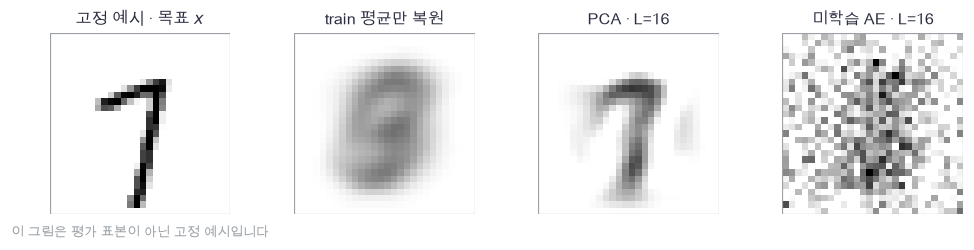

In [33]:
plot_comparison_setup(example_images[7], train_mean.reshape(28, 28), example_pca[7].reshape(28, 28), example_initial[7].reshape(28, 28), LATENT_DIM)

🔍 **그림 확인**

평균 이미지는 모든 입력에 똑같이 나옵니다. PCA는 train의 16개 방향을 사용합니다. 미학습 AE는 같은 크기의 병목을 지나지만 데이터에서 복원 규칙을 배우지 않았습니다. 학습 AE와의 차이를 보면 **병목 구조를 둔 효과**와 **실제로 학습한 효과**를 분리할 수 있습니다. PCA와 AE의 파라미터 수·최적화 방식은 다르므로 잠재 차원을 맞췄다고 모든 계산 조건까지 같아지는 것은 아닙니다.

이제 04번의 Adam을 본문에서 다시 구현합니다. 미니배치 손실의 기울기를 $g_t$라 하면

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,$$
$$\widehat m_t=\frac{m_t}{1-\beta_1^t},\quad \widehat v_t=\frac{v_t}{1-\beta_2^t},\qquad \theta_t=\theta_{t-1}-\eta\frac{\widehat m_t}{\sqrt{\widehat v_t}+\varepsilon}.$$

배치는 최대 128장, 학습률은 $0.003$입니다. 마지막 작은 배치도 포함합니다. 학습 기록의 train MSE는 각 배치를 갱신하기 **직전**의 오차를 표본 수로 가중평균한 값이고, validation MSE는 epoch가 끝난 한 모델의 오차입니다. 서로 다른 시점의 값이므로 두 곡선의 차이를 그대로 일반화 격차라고 해석하지 않습니다.

> **용어** · **미니배치(minibatch)**는 한 번의 기울기 계산에 함께 넣는 일부 표본입니다. 이번에는 최대 128장을 한 배치로 씁니다.

> **코드** · 학습 루프의 `rng.permutation(N)`은 0부터 N−1까지의 표본 번호를 섞습니다. `params = {name: values.copy() for ...}`는 이름마다 독립 복사본을 만드는 사전 내포입니다. 가중치 사본을 갱신해도 초기 기준선은 바뀌지 않습니다.

In [34]:
def adam_update(params, gradients, moments, squares, step, learning_rate):
    """같은 step의 모든 파라미터를 편향 보정한 Adam으로 제자리 갱신합니다."""
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    for name in params:
        gradient = gradients[name]
        moments[name] = beta1 * moments[name] + (1 - beta1) * gradient
        squares[name] = beta2 * squares[name] + (1 - beta2) * gradient ** 2
        corrected_moment = moments[name] / (1 - beta1 ** step)
        corrected_square = squares[name] / (1 - beta2 ** step)
        params[name] -= learning_rate * corrected_moment / (np.sqrt(corrected_square) + epsilon)

In [35]:
# 쓰는 것: ae_forward, ae_backward (3절), reconstruction_loss (1절), adam_update (4절)
def train_ae(clean_train, validation_input, validation_target, initial,
             noise_std=0.0, epochs=8, batch_size=128, learning_rate=0.003, seed=226):
    """초깃값을 복사하고 깨끗한 타깃으로 AE 또는 잡음 제거 AE를 학습합니다."""
    # 1) 각 실험의 가중치·Adam 상태·표본 순서·잡음 난수를 독립시킵니다.
    params = {name: values.copy() for name, values in initial.items()}
    moments = {name: np.zeros_like(values) for name, values in params.items()}
    squares = {name: np.zeros_like(values) for name, values in params.items()}
    order_rng = np.random.default_rng(seed)
    noise_rng = np.random.default_rng(seed + 1)
    step = 0
    history = []
    for epoch in range(1, epochs + 1):
        order = order_rng.permutation(len(clean_train))
        total_loss = 0.0
        # 2) 입력에만 잡음을 더합니다. noise_std=0이면 보통 AE와 같습니다.
        for start in range(0, len(order), batch_size):
            target = clean_train[order[start:start + batch_size]]
            batch_input = target
            if noise_std > 0:
                batch_input = target + noise_std * noise_rng.normal(size=target.shape)
            # 3) forward → loss → backward → update를 모든 배치에서 반복합니다.
            restored, cache = ae_forward(batch_input, params)
            loss, drestored = reconstruction_loss(restored, target)
            _, gradients = ae_backward(drestored, cache, params)
            step += 1
            adam_update(params, gradients, moments, squares, step, learning_rate)
            total_loss += loss * len(target)
        # 4) validation 입력은 호출할 때 정해 둔 배열 그대로 사용합니다.
        valid_restored, _ = ae_forward(validation_input, params)
        valid_loss, _ = reconstruction_loss(valid_restored, validation_target)
        train_mse = 2 * total_loss / len(clean_train)
        valid_mse = 2 * valid_loss
        assert np.isfinite(train_mse + valid_mse), "학습·검증 손실은 유한해야 합니다"
        history.append([epoch, train_mse, valid_mse])
        print(f"epoch {epoch:2d}: train MSE={train_mse:.5f}, validation MSE={valid_mse:.5f}")
    return params, np.asarray(history)

In [36]:
# Adam 첫 단계의 편향 보정과 부호를 독립적인 두 좌표로 확인합니다.
adam_probe = {"w": np.array([1., -2.])}
adam_gradient = {"w": np.array([2., -4.])}
adam_moment = {"w": np.zeros(2)}
adam_square = {"w": np.zeros(2)}
adam_update(adam_probe, adam_gradient, adam_moment, adam_square, 1, 0.01)
np.testing.assert_allclose(adam_probe["w"], [0.99, -1.99], atol=1e-9)  # 검산: 첫 단계는 기울기 부호 반대 방향으로 약 0.01 이동합니다.
print("Adam 첫 갱신 검산 통과")

Adam 첫 갱신 검산 통과


In [37]:
# 쓰는 것: train_centered, valid_centered, initial_params, EPOCHS (4절 데이터 설정)
clean_params, clean_history = train_ae(
    train_centered, valid_centered, valid_centered, initial_params, epochs=EPOCHS,
)

epoch  1: train MSE=0.07358, validation MSE=0.05211
epoch  2: train MSE=0.04493, validation MSE=0.03724


epoch  3: train MSE=0.03555, validation MSE=0.03243
epoch  4: train MSE=0.03142, validation MSE=0.02966
epoch  5: train MSE=0.02925, validation MSE=0.02828
epoch  6: train MSE=0.02808, validation MSE=0.02745
epoch  7: train MSE=0.02747, validation MSE=0.02710


epoch  8: train MSE=0.02717, validation MSE=0.02687


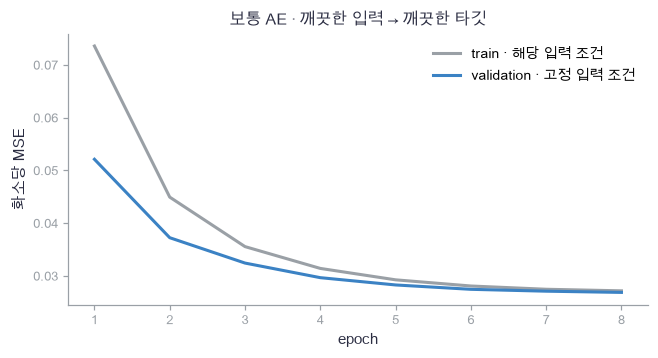

In [38]:
plot_training_history(clean_history, "보통 AE · 깨끗한 입력 → 깨끗한 타깃")

🔍 **학습 기록 확인**

초기 잡음 같은 복원에서 화소당 오차가 줄어드는지 봅니다. 검증 오차가 줄지 않거나 유한하지 않으면 평가 그림을 해석하기 전에 학습률·데이터·기울기 검산을 확인합니다. 여기서는 큰 모델이나 긴 학습으로 최저 오차를 찾는 대신, 정해 둔 작은 실험을 끝까지 실행합니다.

이제 별도 test 파일 800장 모두에서 MSE를 계산합니다. 아래 표의 분모는 모든 모델에서 똑같이 $800\times784$입니다. 그림은 그중 앞 8장만 보여 주므로 **그림 8장의 인상과 전체 800장 지표를 구별**합니다.

In [39]:
# 쓰는 것: ae_forward (3절), reconstruct_pca (2절), train_mean, test_raw, test_centered, pca_basis, initial_params (4절)
test_initial_centered, _ = ae_forward(test_centered, initial_params)
test_clean_centered, _ = ae_forward(test_centered, clean_params)
_, test_pca_raw = reconstruct_pca(test_raw, train_mean, pca_basis)
test_clean_raw = test_clean_centered + train_mean
clean_metrics = {
    "평균만": np.mean(test_centered ** 2),
    "PCA (L=16)": np.mean((test_pca_raw - test_raw) ** 2),
    "미학습 AE (L=16)": np.mean((test_initial_centered - test_centered) ** 2),
    "학습 AE (L=16)": np.mean((test_clean_centered - test_centered) ** 2),
}
for name, value in clean_metrics.items():
    print(f"{name:20s} test MSE = {value:.6f}")
assert clean_metrics["학습 AE (L=16)"] < clean_metrics["미학습 AE (L=16)"], "이 고정 실험에서는 학습 후 MSE가 미학습보다 낮아야 합니다"
np.testing.assert_allclose(test_clean_raw - test_raw, test_clean_centered - test_centered, atol=1e-15)  # 검산: 같은 평균을 더하면 잔차는 바뀌지 않습니다.

평균만                  test MSE = 0.065071
PCA (L=16)           test MSE = 0.027864
미학습 AE (L=16)        test MSE = 0.121153
학습 AE (L=16)         test MSE = 0.028591


In [40]:
# 쓰는 것: test_raw, test_pca_raw, test_initial_centered, train_mean, test_clean_raw (4절 독립 평가)
clean_display = np.stack([
    test_raw[:8], test_pca_raw[:8], test_initial_centered[:8] + train_mean, test_clean_raw[:8],
]).reshape(4, 8, 28, 28)

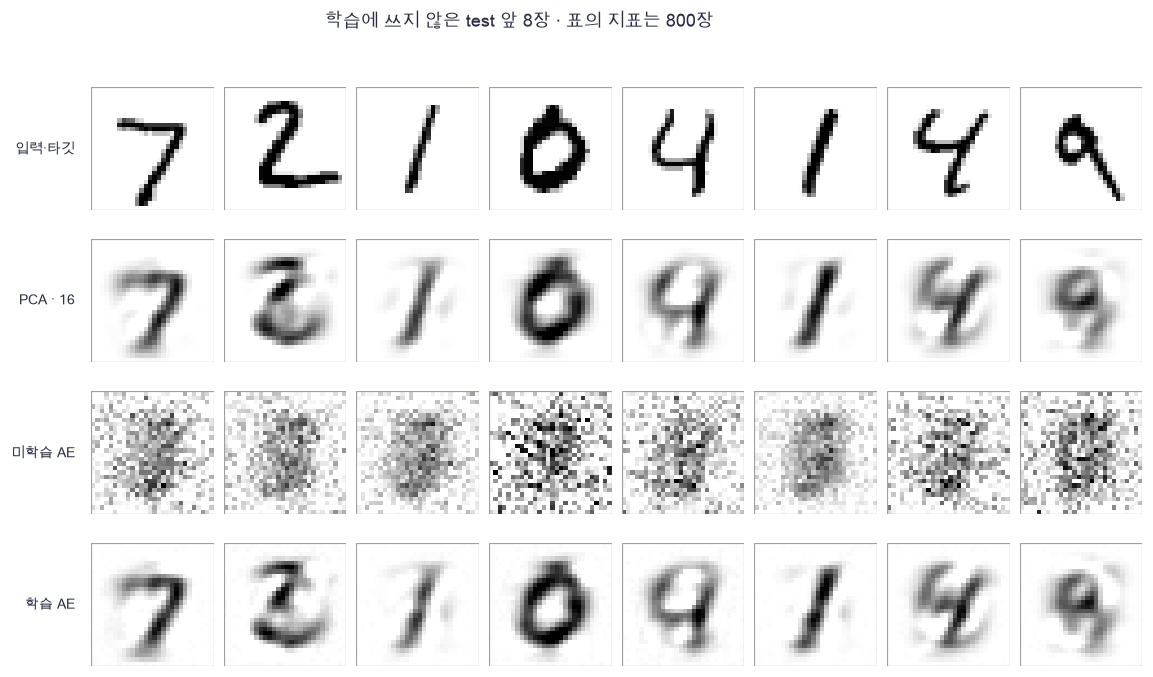

In [41]:
plot_reconstruction_rows(clean_display, ["입력·타깃", "PCA · 16", "미학습 AE", "학습 AE"], "학습에 쓰지 않은 test 앞 8장 · 표의 지표는 800장")

🔍 **복원 결과 확인**

PCA와 AE 중 어느 쪽 MSE가 작은지는 실제 표를 읽습니다. PCA의 최적성은 **train의 선형 rank-$L$ 복원**에 관한 것이므로 비선형 AE의 test MSE까지 순서를 보장하지 않습니다. 획이 부드럽게 뭉개져도 평균 제곱오차는 작을 수 있습니다. 이 표는 같은 데이터와 고정 설정에서의 복원 비교이며, 그림의 자연스러움이나 생성 모델의 품질 전체를 재는 지표는 아닙니다.

### ✏️ 연습 4 · 표본 수가 다른 배치의 MSE 합치기

배치별 MSE `batch_mse`와 표본 수 `counts`가 주어집니다. 단순 평균이 아니라 표본 수로 가중한 `overall` 한 줄을 채우세요. 모든 표본의 화소 수는 같습니다.

In [42]:
def exercise_weighted_mse(batch_mse, counts):
    """마지막 작은 배치까지 포함해 전체 표본 평균 MSE를 계산합니다."""
    raise NotImplementedError
    return overall

In [43]:
def check_weighted_mse(candidate):
    """세 표본의 오차가 1,1,4일 때 전체 평균 2를 검사합니다."""
    actual = candidate(np.array([1., 4.]), np.array([2, 1]))
    np.testing.assert_allclose(actual, 2.)  # 검산: (1·2+4·1)/(2+1)=2이며 배치 단순 평균 2.5가 아닙니다.
run_check(check_weighted_mse, exercise_weighted_mse)

☐ exercise_weighted_mse: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
overall = np.sum(batch_mse * counts) / np.sum(counts)
```

</details>

## 🔑 5. 잡음을 지우는 목적과 생성 모델의 경계

**이 절에서 가져갈 것:** 손상된 입력과 깨끗한 타깃을 분리하고, 고정한 잡음으로 실제 모델을 검산한 뒤, 보통 AE에 없는 생성 규칙을 설명합니다.

숫자 사진에 센서 잡음이 섞였다고 합시다. 보통 AE에 이 사진을 넣어 같은 사진을 타깃으로 삼으면 잡음까지 복원하라고 가르치게 됩니다. 잡음을 제거하려면 **입력만 손상시키고 타깃은 깨끗하게 둡니다.**

> **용어** · **denoising AE(잡음 제거 AE)**는 손상 입력에서 깨끗한 입력을 복원하도록 학습하는 AE입니다. **손상 과정(corruption)**은 깨끗한 데이터에 잡음을 더하거나 일부 값을 지우는 규칙입니다.

여기서는 독립 표준정규 잡음 $\epsilon$을 화소마다 뽑아 $\widetilde X=X+\sigma\epsilon$으로 만듭니다. $\sigma=0.3$은 화소 범위 0–1에 비해 눈에 보이는 크기입니다. 입력 값을 범위 안으로 자르지 않고 이 규칙 그대로 학습·평가합니다.

$$J_{\mathrm{DAE}}(\theta)=\mathbb E_\epsilon\left[\frac1{2ND}\|F_\theta(X+\sigma\epsilon)-X\|_F^2\right].$$

각 미니배치에서 새 잡음 하나를 뽑으면 이 기대 손실의 샘플 값을 계산합니다. 파라미터를 미분할 때 잡음과 타깃은 상수입니다. 파라미터에 의존하지 않는 손상 과정이므로 같은 backward를 그대로 씁니다. 중심화한 자료에서는 $(X-m)+\sigma\epsilon$을 입력하고 $X-m$을 타깃으로 둡니다.

In [44]:
# 쓰는 것: example_images (3절 고정 예시)
NOISE_STD = 0.3
illustration_rng = np.random.default_rng(230)
illustration_noise = NOISE_STD * illustration_rng.normal(size=(28, 28))
illustration_noisy = example_images[7] + illustration_noise

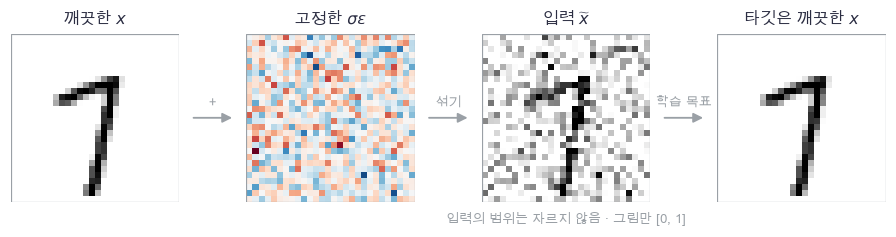

In [45]:
plot_denoising_flow(example_images[7], illustration_noise, illustration_noisy, example_images[7])

🔍 **그림 확인**

셋째 판은 신경망에 넣는 손상 입력이고, 넷째 판은 손실에서 비교하는 깨끗한 타깃입니다. 두 판이 다르다는 점이 핵심입니다. 잡음 생성과 모델 계산을 분리하면, 검산의 $\theta+h$와 $\theta-h$에서 같은 입력을 사용할 수 있습니다. 양쪽에서 새 잡음을 뽑으면 중심차분의 차이에 잡음 변화까지 섞입니다.

In [46]:
def corrupt_input(clean, noise_std, epsilon):
    """밖에서 고정한 잡음을 입력에만 더하며 원본 배열은 바꾸지 않습니다."""
    assert clean.shape == epsilon.shape, "깨끗한 입력과 잡음의 shape가 같아야 합니다"
    assert noise_std >= 0, "잡음 표준편차는 음수가 될 수 없습니다"
    return clean + noise_std * epsilon

In [47]:
# 쓰는 것: small_x, small_target, small_params, check_ae_gradients (3절 작은 모델), NOISE_STD (5절)
noise_check_rng = np.random.default_rng(231)
fixed_small_epsilon = noise_check_rng.normal(size=small_x.shape)
fixed_noisy_input = corrupt_input(small_x, NOISE_STD, fixed_small_epsilon)
noisy_gradient_reports = check_ae_gradients(fixed_noisy_input, small_target, small_params)
no_noise_input = corrupt_input(small_x, 0.0, fixed_small_epsilon)
np.testing.assert_array_equal(no_noise_input, small_x)  # 검산: 잡음 크기 0이면 입력이 정확히 원래 값입니다.
np.testing.assert_array_equal(small_target, small_x)  # 검산: 손상 과정·수치미분 뒤에도 깨끗한 타깃이 유지됩니다.
print("고정 잡음에서 실제 AE의 모든 파라미터·입력 검산 통과")
print("최대 상대오차:", max(row[2] for row in noisy_gradient_reports))

고정 잡음에서 실제 AE의 모든 파라미터·입력 검산 통과
최대 상대오차: 3.12798789628247e-10


📎 **같은 잡음 조건에서 비교하기**

학습 때는 배치마다 새 잡음을 뽑지만, validation과 test의 잡음은 별도 seed로 **한 번만 생성해 고정**합니다. 따라서 epoch별 validation 변화는 모델 변화이고, 같은 test에서의 모델 차이는 같은 손상 입력에 대한 차이입니다. 한 번의 잡음 추첨 결과이므로 이것만으로 모든 잡음 조건의 평균 성능을 확정하지는 않습니다.

보통 AE와 DAE는 같은 초기 가중치·구조·학습 표본·표본 순서·epoch·Adam 설정을 씁니다. 차이는 학습 입력을 손상시키는지입니다. **보통 AE에 noisy 입력을 넣는 비교는 깨끗한 입력으로 배운 모델의 손상 견딤을 보는 검사**입니다. DAE와 동일한 목적을 학습한 모델이라고 해석하지 않습니다. PCA 역시 깨끗한 train으로 맞춘 기저를 고정해 사용합니다.

In [48]:
# 쓰는 것: valid_centered, test_centered (4절), NOISE_STD, corrupt_input (5절)
validation_noise_rng = np.random.default_rng(232)
test_noise_rng = np.random.default_rng(233)
valid_epsilon = validation_noise_rng.normal(size=valid_centered.shape)
test_epsilon = test_noise_rng.normal(size=test_centered.shape)
valid_noisy = corrupt_input(valid_centered, NOISE_STD, valid_epsilon)
test_noisy = corrupt_input(test_centered, NOISE_STD, test_epsilon)

In [49]:
# 쓰는 것: train_ae, train_centered, valid_centered, initial_params, EPOCHS (4절), NOISE_STD (5절)
denoising_params, denoising_history = train_ae(
    train_centered, valid_noisy, valid_centered, initial_params,
    noise_std=NOISE_STD, epochs=EPOCHS,
)

epoch  1: train MSE=0.08900, validation MSE=0.05650
epoch  2: train MSE=0.04988, validation MSE=0.04082


epoch  3: train MSE=0.03930, validation MSE=0.03589
epoch  4: train MSE=0.03490, validation MSE=0.03262
epoch  5: train MSE=0.03241, validation MSE=0.03119


epoch  6: train MSE=0.03122, validation MSE=0.03026


epoch  7: train MSE=0.03037, validation MSE=0.02974
epoch  8: train MSE=0.02982, validation MSE=0.02928


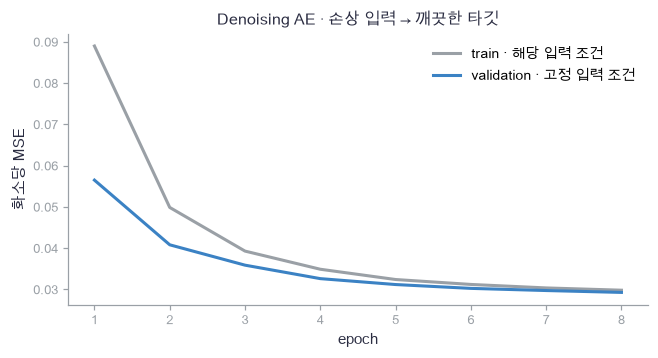

In [50]:
plot_training_history(denoising_history, "Denoising AE · 손상 입력 → 깨끗한 타깃")

In [51]:
# 쓰는 것: ae_forward (3절), clean_params, test_centered, pca_basis, train_mean (4절), test_noisy (5절)
noisy_identity_mse = np.mean((test_noisy - test_centered) ** 2)
noisy_pca_centered = (test_noisy @ pca_basis) @ pca_basis.T
noisy_clean_ae, _ = ae_forward(test_noisy, clean_params)
noisy_denoising_ae, _ = ae_forward(test_noisy, denoising_params)
clean_denoising_ae, _ = ae_forward(test_centered, denoising_params)
noise_metrics = {
    "손상 입력 그대로": noisy_identity_mse,
    "PCA에 손상 입력": np.mean((noisy_pca_centered - test_centered) ** 2),
    "보통 AE에 손상 입력": np.mean((noisy_clean_ae - test_centered) ** 2),
    "DAE에 손상 입력": np.mean((noisy_denoising_ae - test_centered) ** 2),
}
for name, value in noise_metrics.items():
    assert np.isfinite(value), "모든 평가 MSE는 유한해야 합니다"
    print(f"{name:20s} test MSE = {value:.6f}")
print("별도 조건 · DAE에 깨끗한 입력:", f"{np.mean((clean_denoising_ae-test_centered)**2):.6f}")

손상 입력 그대로            test MSE = 0.089976
PCA에 손상 입력           test MSE = 0.029686
보통 AE에 손상 입력         test MSE = 0.037458
DAE에 손상 입력           test MSE = 0.030997
별도 조건 · DAE에 깨끗한 입력: 0.029088


In [52]:
# 쓰는 것: test_raw, train_mean (4절), test_noisy, noisy_clean_ae, noisy_denoising_ae (5절 독립 평가)
noise_display = np.stack([
    test_raw[:8], test_noisy[:8] + train_mean,
    noisy_clean_ae[:8] + train_mean, noisy_denoising_ae[:8] + train_mean,
]).reshape(4, 8, 28, 28)

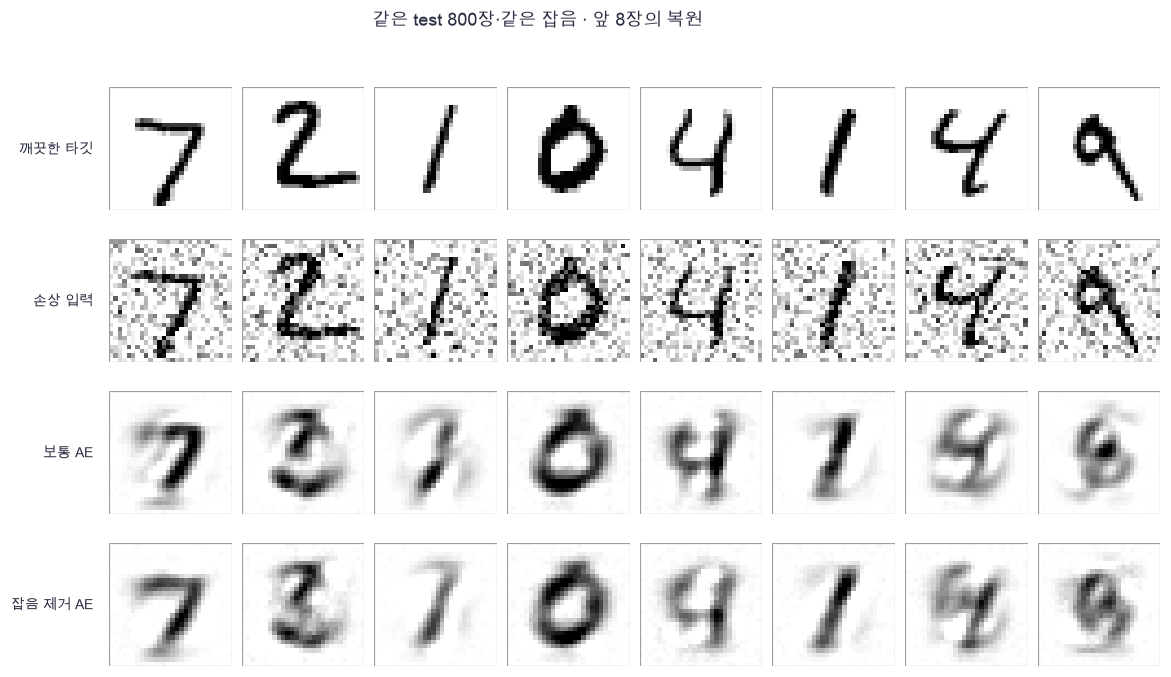

In [53]:
plot_reconstruction_rows(noise_display, ["깨끗한 타깃", "손상 입력", "보통 AE", "잡음 제거 AE"], "같은 test 800장·같은 잡음 · 앞 8장의 복원")

🔍 **잡음 제거 결과 확인**

손상 입력을 그대로 반환하면 기대 MSE는 $\sigma^2=0.09$입니다. 표의 유한 표본 값은 이 근처인지 확인합니다. PCA와 두 AE의 순서는 실제 수치를 읽습니다. 잡음을 줄이면서 가는 획까지 지웠는지, 원래 없던 획을 만들었는지 함께 봅니다. DAE의 목적은 복원을 돕는 표현을 배우는 것이며, 입력마다 언제나 올바른 숫자를 되살리는 보증은 아닙니다.

**보통 AE와 DAE는 왜 곧바로 생성 모델이 아닐까요?** 학습한 것은 주어진 입력을 거친 $g(f(x))$의 복원입니다. 새로운 입력 없이 decoder만 쓰려면 **어디서 $z$를 뽑을지**가 추가로 필요합니다.

> **용어** · **잠재 사전분포(prior) $p(z)$**는 입력을 보기 전에 잠재값을 뽑는 확률 규칙입니다. 이 노트북의 보통 AE와 DAE 손실에는 그런 분포가 들어 있지 않습니다.

2절의 좌표를 세 배로 바꿔도 모든 복원은 그대로였습니다. 그런데 양쪽 decoder에 같은 $z\sim\mathcal N(0,I)$를 넣으면 출력은 서로 달라집니다. 선형 decoder $W_d$의 출력 공분산은 $W_d^TW_d$이므로, $W_d/3$에서는 그 $1/9$입니다. 재구성 목적만으로 임의의 정규분포를 잠재 분포로 정당화할 수 없다는 작은 반례입니다.

In [54]:
# 쓰는 것: toy_basis, scaled_decoder (2절 같은 복원을 주는 두 decoder)
original_output_cov = toy_basis @ toy_basis.T
scaled_output_cov = scaled_decoder.T @ scaled_decoder
np.testing.assert_allclose(scaled_output_cov, original_output_cov / 9)  # 검산: 같은 정규 잠재 샘플 규칙에서 출력 공분산은 아홉 배 다릅니다.
print("같은 재구성 함수라도 임의의 정규 잠재 입력에 대한 출력 분포는 다릅니다.")

같은 재구성 함수라도 임의의 정규 잠재 입력에 대한 출력 분포는 다릅니다.


📎 **27과 25로 이어지는 질문**

[27 · 샘플 추정과 기울기](27_monte_carlo_gradients.ipynb)에서는 “기대값을 샘플 몇 개로 계산하면 얼마나 흔들리는가, 양쪽 검산에서 무엇을 고정해야 하는가”를 따로 다룹니다. 여기서는 손상 잡음이 모델 파라미터와 독립이라 고정 잡음 한 번에 대한 ordinary backward를 계산했습니다.

[25 · VAE](25_vae.ipynb)는 입력마다 잠재 분포 $q_\phi(z\mid x)$를 만들고, decoder의 관측 분포 $p_\theta(x\mid z)$와 사전분포 $p(z)$를 연결합니다. 목적도 단순 MSE가 아니라 재구성 항과 KL 항으로 구성한 **ELBO**로 바뀝니다. 그 뒤에는 정한 $p(z)$에서 뽑아 decoder로 보내는 생성 규칙이 있습니다. 다만 VAE의 품질도 별도로 평가해야 합니다. 이 노트북에서 `tanh`나 병목 크기만 바꾸는 것으로 그 확률모형과 목적이 생기는 것은 아닙니다.

### ✏️ 연습 5 · 손상 입력과 깨끗한 타깃 만들기

`clean`, 미리 뽑은 `epsilon`, 잡음 크기 `sigma`를 받습니다. 입력 `noisy`와 원본에서 독립적으로 복사한 `target`을 두 줄로 채우세요.

In [55]:
def exercise_denoising_pair(clean, epsilon, sigma):
    """손상된 입력과 변하지 않는 깨끗한 타깃을 만듭니다."""
    raise NotImplementedError
    return noisy, target

In [56]:
def check_denoising_pair(candidate):
    """입력에는 잡음을 더하고 타깃은 손계산의 원본으로 유지하는지 검사합니다."""
    clean = np.array([[0., 1.]])
    noisy, target = candidate(clean, np.array([[1., -2.]]), 0.1)
    np.testing.assert_allclose(noisy, [[0.1, 0.8]])  # 검산: 0+0.1과 1-0.2입니다.
    np.testing.assert_allclose(target, [[0., 1.]])  # 검산: 타깃에는 잡음이 없습니다.
    assert not np.shares_memory(target, clean), "타깃을 별도 복사하면 입력 검산에서 함께 변하지 않습니다"
run_check(check_denoising_pair, exercise_denoising_pair)

☐ exercise_denoising_pair: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
noisy = clean + sigma * epsilon
target = clean.copy()
```

</details>

## ✏️ 전체 연결 연습 A–D

아래 문제는 긴 학습을 다시 실행하지 않고 작은 배열만으로 검사합니다. 어떤 축을 합하는지 먼저 손으로 쓰고, 그다음 한두 줄을 채워 보세요.

### ✏️ 연습 A · 재구성 손실의 평균 축

`restored`, `target`의 shape는 `(N,D)`입니다. 손실 $J=\|R-T\|^2/(2ND)$와 출력 기울기 `gradient`를 두 줄로 채우세요.

In [57]:
def exercise_reconstruction_objective(restored, target):
    """표본·화소를 모두 평균한 손실과 출력 기울기를 구합니다."""
    residual = restored - target
    raise NotImplementedError
    return loss, gradient

In [58]:
def check_reconstruction_objective(candidate):
    """잔차가 1,-1인 한 표본에서 손실 0.5와 평균 기울기를 검사합니다."""
    loss, gradient = candidate(np.array([[2., 0.]]), np.array([[1., 1.]]))
    np.testing.assert_allclose(loss, 0.5)  # 검산: (1+1)/(2·1·2)=0.5입니다.
    np.testing.assert_allclose(gradient, [[0.5, -0.5]])  # 검산: 잔차를 두 화소로 나눕니다.
run_check(check_reconstruction_objective, exercise_reconstruction_objective)

☐ exercise_reconstruction_objective: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = 0.5 * np.mean(residual ** 2)
gradient = residual / target.size
```

</details>

### ✏️ 연습 B · 복원을 유지하며 잠재 단위 바꾸기

선형 encoder `we`, decoder `wd`와 양수 `scale`이 주어집니다. 잠재 좌표를 `scale`배로 바꾸되 복원을 유지하는 두 가중치를 채우세요.

In [59]:
def exercise_rescale_latent(we, wd, scale):
    """encoder의 확대를 decoder에서 상쇄합니다."""
    raise NotImplementedError
    return new_we, new_wd

In [60]:
def check_rescale_latent(candidate):
    """세 배로 바꾼 가중치의 곱을 독립적인 손계산 투영과 비교합니다."""
    new_we, new_wd = candidate(np.array([[1.], [0.]]), np.array([[1., 0.]]), 3.)
    np.testing.assert_allclose(new_we, [[3.], [0.]])  # 검산: encoder가 잠재 좌표를 세 배로 만듭니다.
    np.testing.assert_allclose(new_we @ new_wd, [[1., 0.], [0., 0.]])  # 검산: 전체 복원 투영은 그대로입니다.
run_check(check_rescale_latent, exercise_rescale_latent)

☐ exercise_rescale_latent: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
new_we = we * scale
new_wd = wd / scale
```

</details>

### ✏️ 연습 C · tanh를 거슬러 올라가기

`activation`은 tanh의 출력이고 `upstream`은 그 출력에 대한 손실 기울기입니다. tanh 입력 기울기 한 줄을 채우세요.

In [61]:
def exercise_tanh_backward(activation, upstream):
    """저장한 tanh 출력으로 입력 기울기를 구합니다."""
    raise NotImplementedError
    return gradient

In [62]:
def check_tanh_backward(candidate):
    """출력 0과 0.5의 도함수 1과 0.75를 검사합니다."""
    actual = candidate(np.array([0., 0.5]), np.array([2., -4.]))
    np.testing.assert_allclose(actual, [2., -3.])  # 검산: 2·1=2, -4·0.75=-3입니다.
run_check(check_tanh_backward, exercise_tanh_backward)

☐ exercise_tanh_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = upstream * (1 - activation ** 2)
```

</details>

### ✏️ 연습 D · 잡음 제거 손실의 타깃 선택

`noisy`는 입력이고 `restored`는 모델 출력입니다. `clean`을 타깃으로 하는 손실 한 줄을 채우세요. 손상 입력과 비교하는 실수를 검사합니다.

In [63]:
def exercise_denoising_loss(noisy, clean, restored):
    """손상 입력 대신 깨끗한 타깃과 복원을 비교합니다."""
    raise NotImplementedError
    return loss

In [64]:
def check_denoising_loss(candidate):
    """깨끗한 타깃에 대한 잔차가 -0.1,+0.1인 손계산을 검사합니다."""
    actual = candidate(np.array([[0.4, 0.6]]), np.array([[1., 0.]]), np.array([[0.9, 0.1]]))
    np.testing.assert_allclose(actual, 0.005)  # 검산: (0.01+0.01)/(2·2)=0.005입니다.
run_check(check_denoising_loss, exercise_denoising_loss)

☐ exercise_denoising_loss: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = 0.5 * np.mean((restored - clean) ** 2)
```

</details>

## ✏️ 다음 단계 준비도

**설명 확인:** encoder·decoder·병목을 한 문장씩 설명할 수 있나요? 같은 잠재 차원이어도 PCA와 비선형 AE가 같은 모델은 아닌 이유는 무엇인가요? DAE에 넣는 입력과 손실의 타깃은 각각 무엇인가요?

**수식 확인:** $J=\|R-T\|^2/(2ND)$에서 $dR$를 유도할 수 있나요? $W_e\mapsto W_eQ$, $W_d\mapsto Q^{-1}W_d$가 복원을 유지함을 행렬 곱으로 보일 수 있나요? PCA 최적 오차가 버린 특잇값 제곱합인 이유를 설명할 수 있나요?

**구현 확인:** 출력층에서 입력까지 네 가중치와 네 편향의 shape를 적으며 backward를 다시 쓸 수 있나요? 학습과 평가에서 같은 train 평균을 사용하는 위치를 찾을 수 있나요? 학습 루프에서 forward·손실·backward·Adam 갱신·평가를 구별할 수 있나요?

**변형 검산:** $L=8$로 바꾸면 어느 가중치의 shape가 변하나요? $σ=0$이면 DAE 입력과 보통 AE 입력이 정확히 같아지는지 확인할 수 있나요? 중심차분에서 잡음을 매번 새로 뽑으면 왜 검사 대상이 바뀌나요? 타깃까지 입력과 함께 흔들 때에는 왜 $-G$를 더해야 하나요?

직접 설정을 바꿀 때는 한 번에 하나만 바꾸고 train/validation으로 비교합니다. test 수치를 반복해서 보고 설정을 골랐다면 그 자료는 더 이상 최종 성능 확인용으로 독립적이지 않습니다. 보통 AE의 좋은 복원에서 곧바로 생성 품질을 결론내리지 말고, 다음에는 **샘플링 규칙과 학습 목적을 따로 적는 일**로 넘어갑니다.

In [65]:
# 쓰는 것: experiment_started (4절 MNIST 실험 시작)
print(f"PCA·두 AE의 학습과 평가 경과 시간: {perf_counter() - experiment_started:.1f}초")

PCA·두 AE의 학습과 평가 경과 시간: 1.7초
